# 01 – Data exploration: Meter B

**Data.** Meter B (UCI *Ultrasonic flowmeter diagnostics*): 92 samples of a 4-path liquid ultrasonic
flow meter, 51 diagnostic features + class (1 = healthy, 2 = gas injection, 3 = waxing).

**Aim of this notebook.**
1. Load the data and check it is what we expect.
2. Remove variables that are constant in the healthy state.
3. Autoscale (z-score) and justify why this is needed for kPCA.
4. Get a first look at which variables change under each fault, and how redundant the variables are.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
names = np.array(kt.FEATURE_NAMES)
short = np.array(kt.SHORT_NAMES)

print("X_raw shape:", X_raw.shape, "  y shape:", y.shape)
print("\nFirst 3 samples, first 6 features:")
print(" ".join(f"{s:>8}" for s in short[:6]))
for row in X_raw[:3, :6]:
    print(" ".join(f"{v:8.3f}" for v in row))

X_raw shape: (92, 51)   y shape: (92,)

First 3 samples, first 6 features:
      PF      SYM       CF      SWA       V1       V2
   1.185    1.028    1.016    0.150    2.196    2.541
   1.192    1.034    1.019    0.217    2.192    2.547
   1.182    1.028    1.021    0.089    3.247    3.738


## 1. Sanity checks
These `assert`s stop the notebook if the data file is not what the rest of the project assumes.

In [2]:
classes, counts = np.unique(y, return_counts=True)

assert X_raw.shape == (92, 51)
assert len(kt.FEATURE_NAMES) == len(kt.SHORT_NAMES) == 51
assert dict(zip(classes, counts)) == {1: 19, 2: 24, 3: 49}
assert not np.isnan(X_raw).any()
assert (X_raw.std(axis=0, ddof=1) > 0).all()        # no column is constant over the whole data set
print("All raw-data checks passed.")

All raw-data checks passed.


## 2. Class balance

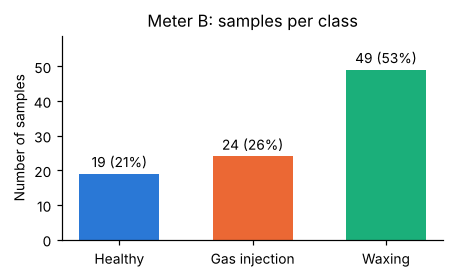

In [3]:
fig, ax = plt.subplots(figsize=(4.2, 2.6))
labels = [kt.CLASS_NAMES[c] for c in classes]
bars = ax.bar(labels, counts, color=[kt.CLASS_COLORS[c] for c in classes], width=0.6)
for b, n in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, n + 1, f"{n} ({n / counts.sum():.0%})",
            ha="center", va="bottom")
ax.set_ylabel("Number of samples")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Meter B: samples per class")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m1_class_counts.png")
plt.show()

The classes are unbalanced: waxing is more than half of the data. Later, when we score how well a
kernel separates the classes, we must use measures that are not dominated by the largest class.

## 3. Variables that are constant in the healthy state

A variable with zero variance contributes nothing to PCA/kPCA: it does not change the distance between
any two samples, so it cannot carry any direction of variation. We therefore check which variables
have **std = 0 within the healthy class** and remove them from the main analysis.

These variables may still change in the faulty classes; if so, they are kept aside and analysed
separately later.

In [4]:
const_idx = kt.constant_columns(X_raw, y, cls=1)

print(f"{len(const_idx)} variables are constant in the healthy class:\n")
print(f"{'#':>3} {'variable':<22} {'healthy':>8} | {'gas: min':>9} {'max':>7} {'#unique':>8} | {'wax: min':>9} {'max':>7} {'#unique':>8}")
for j in const_idx:
    h = X_raw[y == 1, j][0]
    g, w = X_raw[y == 2, j], X_raw[y == 3, j]
    print(f"{j + 1:>3} {names[j]:<22} {h:8.1f} | {g.min():9.1f} {g.max():7.1f} {np.unique(g).size:8d} "
          f"| {w.min():9.1f} {w.max():7.1f} {np.unique(w).size:8d}")

11 variables are constant in the healthy class:

  # variable                healthy |  gas: min     max  #unique |  wax: min     max  #unique
 27 Meter performance         100.0 |      41.3   100.0       24 |      61.4    98.2       47
 28 Signal quality P1A        100.0 |       8.7   100.0       24 |      55.5   100.0       19
 29 Signal quality P1B        100.0 |       9.7   100.0       24 |      63.1   100.0       19
 30 Signal quality P2A        100.0 |      25.3   100.0       19 |      89.0   100.0       16
 31 Signal quality P2B        100.0 |      27.8   100.0       19 |      89.0   100.0       16
 32 Signal quality P3A        100.0 |      47.4   100.0       13 |      92.3   100.0       16
 33 Signal quality P3B        100.0 |      48.1   100.0       12 |      92.3   100.0       16
 34 Signal quality P4A        100.0 |      58.4   100.0        9 |       0.0    92.3       44
 35 Signal quality P4B        100.0 |      58.4   100.0        9 |       0.1    92.6       48
 36 Gain P1

In [5]:
keep_idx = np.setdiff1d(np.arange(X_raw.shape[1]), const_idx)
X = X_raw[:, keep_idx]
names_k, short_k = names[keep_idx], short[keep_idx]
X_aside = X_raw[:, const_idx]                       # analysed separately later

print("Kept for kPCA:", X.shape[1], "variables;  set aside:", X_aside.shape[1])

Kept for kPCA: 40 variables;  set aside: 11


**Observation.** All 11 removed variables (meter performance, the 8 signal-quality values and the
gain at both ends of path 1) are fixed at their nominal value in the healthy state, but they **do vary in
both fault classes**. They are therefore potentially strong fault indicators. Removing them keeps the kPCA
analysis focused on variables that vary in normal operation; we will come back to them separately.

## 4. Feature scales and autoscaling

The kernels we will use (Gaussian, Cauchy, …) depend on the Euclidean distance $\lVert x - y \rVert$.
If the variables are on very different scales, the large-valued ones dominate that distance.

In [6]:
sd = X.std(axis=0, ddof=1)
print(f"{'variable':<24} {'min':>10} {'max':>10} {'std':>10}")
for n, lo, hi, s in zip(names_k, X.min(0), X.max(0), sd):
    print(f"{n:<24} {lo:10.3f} {hi:10.3f} {s:10.3f}")
print(f"\nLargest std / smallest std = {sd.max() / sd.min():.0f}")

variable                        min        max        std
Profile factor               -0.909     10.208      1.162
Symmetry                     -0.000      1.498      0.431
Crossflow                    -0.005      1.993      0.432
Swirl angle                  -1.410      2.200      0.818
Flow velocity P1             -0.068      7.454      1.865
Flow velocity P2              0.882      8.844      2.121
Flow velocity P3              1.299      8.497      1.980
Flow velocity P4              0.000      7.105      2.049
Average flow velocity         1.256      8.250      1.900
Speed of sound P1            41.150   1550.967    271.068
Speed of sound P2           255.359   1515.027    144.715
Speed of sound P3          1101.851   1517.164     47.645
Speed of sound P4             0.000   1551.575    561.988
Average speed of sound     1477.819   1527.774     16.062
Signal strength P1A         107.907   5663.906   2109.867
Signal strength P1B         108.825   5319.572   1941.199
Signal strengt

The standard deviations differ by several orders of magnitude, so we autoscale every variable:

$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}, \qquad s_j = \sqrt{\tfrac{1}{n-1}\textstyle\sum_i (x_{ij}-\bar{x}_j)^2}$$

After this, each variable has mean 0 and variance 1, so each contributes equally to the distance.
The mean and std are computed over all 92 samples (kPCA is fitted on all of them).

In [7]:
Z, mu, sigma = kt.zscore(X)

assert np.allclose(Z.mean(axis=0), 0)
assert np.allclose(Z.std(axis=0, ddof=1), 1)
print("Z shape:", Z.shape, "- every column now has mean 0 and std 1.")

Z shape: (92, 40) - every column now has mean 0 and std 1.


## 5. Which variables shift under each fault?
Mean of each autoscaled variable per class. Values far from 0 (dark blue or dark red) mean that
the class sits far from the overall average for that variable.

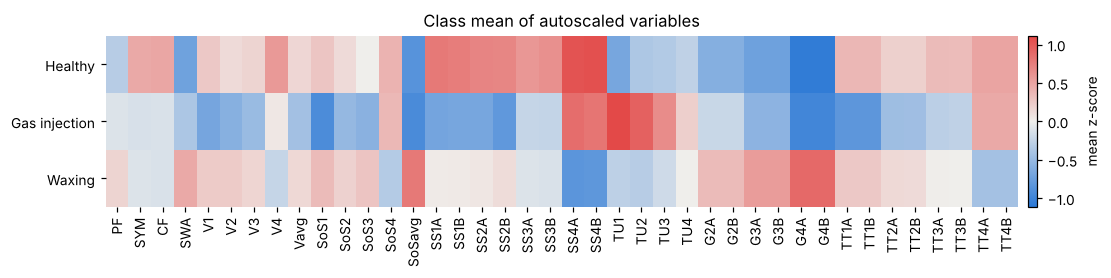

10 variables with the largest class-mean shift:
  TU1     Turbulence P1            Healthy: -0.68  Gas injection: +1.11  Waxing: -0.28
  G4A     Gain P4A                 Healthy: -1.07  Gas injection: -0.97  Waxing: +0.89
  G4B     Gain P4B                 Healthy: -1.07  Gas injection: -0.97  Waxing: +0.89
  SS4B    Signal strength P4B      Healthy: +1.06  Gas injection: +0.81  Waxing: -0.81
  SS4A    Signal strength P4A      Healthy: +1.04  Gas injection: +0.87  Waxing: -0.83
  TU2     Turbulence P2            Healthy: -0.37  Gas injection: +0.94  Waxing: -0.32
  SoSavg  Average speed of sound   Healthy: -0.86  Gas injection: -0.92  Waxing: +0.78
  SoS1    Speed of sound P1        Healthy: +0.28  Gas injection: -0.92  Waxing: +0.34
  TT1A    Transit time P1A         Healthy: +0.37  Gas injection: -0.82  Waxing: +0.26
  TT1B    Transit time P1B         Healthy: +0.37  Gas injection: -0.82  Waxing: +0.26


In [8]:
class_means = np.array([Z[y == c].mean(axis=0) for c in classes])
vmax = np.abs(class_means).max()

fig, ax = plt.subplots(figsize=(11, 2.6))
im = ax.imshow(class_means, cmap=kt.DIVERGING_CMAP, vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_yticks(range(len(classes)), [kt.CLASS_NAMES[c] for c in classes])
ax.set_xticks(range(len(short_k)), short_k, rotation=90)
ax.set_title("Class mean of autoscaled variables")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, pad=0.01, label="mean z-score")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m1_class_means_heatmap.png")
plt.show()

order = np.argsort(-np.abs(class_means).max(axis=0))[:10]
print("10 variables with the largest class-mean shift:")
for j in order:
    print(f"  {short_k[j]:<7} {names_k[j]:<24}", "  ".join(f"{kt.CLASS_NAMES[c]}: {m:+.2f}" for c, m in zip(classes, class_means[:, j])))

## 6. Correlation between variables
Strong blocks of correlation mean the 40 variables carry much less than 40 independent pieces of
information. This redundancy is what PCA-type methods exploit.

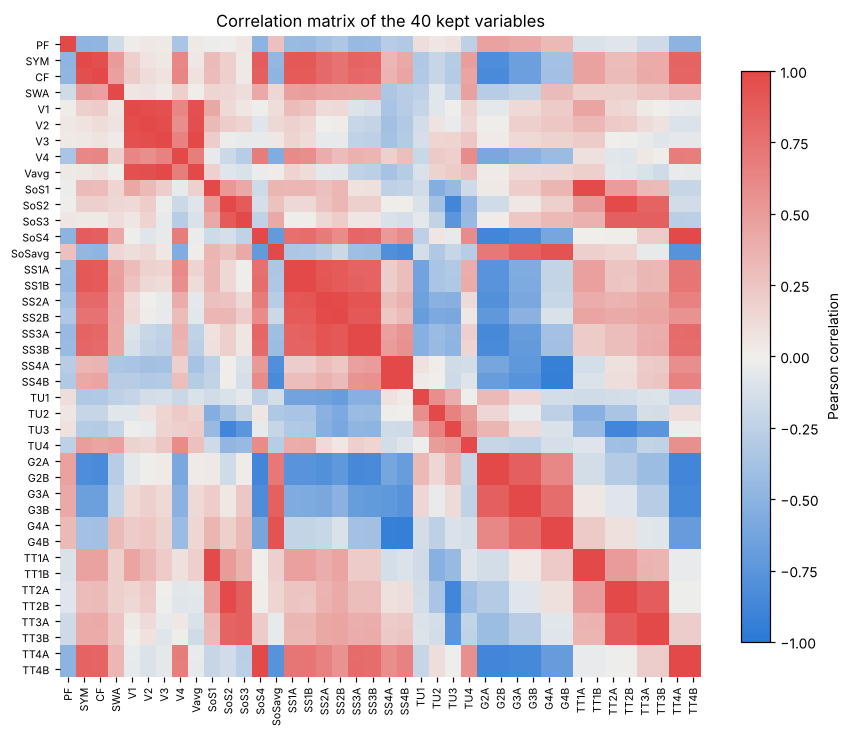

Variable pairs with |r| > 0.9: 35 of 780
Exactly identical variable pairs: [('G2A', 'G2B'), ('G3A', 'G3B'), ('G4A', 'G4B')]


In [9]:
R = np.corrcoef(Z, rowvar=False)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(R, cmap=kt.DIVERGING_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(short_k)), short_k, rotation=90, fontsize=7)
ax.set_yticks(range(len(short_k)), short_k, fontsize=7)
ax.set_title("Correlation matrix of the 40 kept variables")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m1_correlation.png")
plt.show()

upper = np.abs(R[np.triu_indices_from(R, k=1)])
print(f"Variable pairs with |r| > 0.9: {(upper > 0.9).sum()} of {upper.size}")

dup = [(str(short_k[a]), str(short_k[b])) for a in range(Z.shape[1]) for b in range(a + 1, Z.shape[1])
       if np.array_equal(X[:, a], X[:, b])]
print("Exactly identical variable pairs:", dup)

**Observation.** The gain at the two ends of each path is recorded as the *same* value (G2A = G2B,
G3A = G3B, G4A = G4B; the same holds for G1A = G1B, which was set aside). Duplicated columns count twice
in the Euclidean distance, so gain has double weight compared with a single variable. We keep them for now
and note this as a choice to revisit.

## 7. Path-4 signal dropout in part of the waxing samples
Some samples contain exact zeros. We check where they are.

In [10]:
zero_rows = np.where((X_raw == 0).sum(axis=1) >= 5)[0]
zero_cols = np.where((X_raw[zero_rows] == 0).all(axis=0))[0]

print(f"{len(zero_rows)} samples (rows {zero_rows[0] + 1}-{zero_rows[-1] + 1}), classes: {np.unique(y[zero_rows])}")
print("have exactly 0 in these variables:")
for j in zero_cols:
    print(f"  {j + 1:>2} {short[j]:<6} {names[j]}")
assert all(j in keep_idx for j in zero_cols)   # these are all kept in the main analysis

other = np.where(X_raw[np.setdiff1d(np.arange(len(y)), zero_rows)] == 0)
print("\nOther zeros elsewhere:", [(int(r) + 1, str(short[c])) for r, c in zip(*other)])

15 samples (rows 78-92), classes: [3]
have exactly 0 in these variables:
   2 SYM    Symmetry
   3 CF     Crossflow
   4 SWA    Swirl angle
   8 V4     Flow velocity P4
  13 SoS4   Speed of sound P4
  21 SS4A   Signal strength P4A
  22 SS4B   Signal strength P4B
  26 TU4    Turbulence P4
  50 TT4A   Transit time P4A
  51 TT4B   Transit time P4B

Other zeros elsewhere: []


**Observation.** In the last 15 waxing samples, every path-4 measurement (velocity, speed of sound,
turbulence, signal strength and transit time at both ends) is exactly 0, together with symmetry,
crossflow and swirl angle. This looks like path 4 losing its signal. Symmetry, crossflow and swirl angle
are computed by comparing the paths, so they drop out too.

Because signal strength and transit time drop out exactly at features 21–22 and 50–51, the
"both ends" columns must be ordered by path (P1A, P1B, P2A, …, P4B), which confirms our naming.

These 15 samples are real waxing cases, so we keep them. They will probably form a separate group in
the kPCA score plots.

## Summary – carried into Milestone 2
- Data loads correctly: 92 × 51, classes 19 / 24 / 49 (unbalanced), no missing values.
- 11 variables are constant in the healthy state (meter performance, signal quality ×8, gain P1A/P1B).
  They are removed from the kPCA analysis, but vary under both faults → analysed separately later.
- The remaining **40 variables** are autoscaled; their raw stds differed by orders of magnitude.
- Several variables shift clearly per class, and many variables are strongly correlated.
- Gain A/B columns are exact duplicates (double weight in distances) – kept for now.
- 15 waxing samples have a full path-4 dropout; expect them as a separate cluster.